# VoltAhead – Random Forest Model Development

## Objective

Develop and evaluate a horizon-aware Random Forest classifier
to predict future EV charging station availability for
30, 40, and 60-minute prediction horizons.

## Development Workflow

1. Dataset loading and chronological development splits
2. Feature preparation
3. Initial Random Forest training
4. Initial model evaluation
5. Hyperparameter tuning
6. Feature selection
7. Class imbalance handling
8. Probability calibration
9. Threshold optimization
10. Optimized model evaluation
11. Model and prediction export

## Evaluation Protocol

All experiments follow the shared VoltAhead dataset
and evaluation protocol.

The primary model selection metric is Class-0 Average
Precision (AP₀) on seen validation stations.

The official test dataset remains untouched until
final model selection is completed.

## 1. Imports and Environment Setup

Import the required libraries, configure the project paths,
and set the random seed for reproducible experiments.

In [80]:
import sys
import platform
import time
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import joblib
import psutil

from sklearn.ensemble import RandomForestClassifier
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

# Configure project root
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

sys.path.insert(0, str(PROJECT_ROOT))

from src.evaluation import (
    validate_prediction_output,
    calculate_classification_metrics,
    evaluate_predictions,
    evaluate_by_horizon,
    evaluate_by_station_group,
    export_evaluation_results
)

# Reproducibility settings
RANDOM_STATE = 42
N_JOBS = 4

np.random.seed(RANDOM_STATE)

print("Project root:", PROJECT_ROOT)
print("Python version:", platform.python_version())
print("Scikit-learn version:", sklearn.__version__)
print("CPU:", platform.machine())
print("CPU cores:", psutil.cpu_count())
print("RAM (GB):", round(psutil.virtual_memory().total / 1024**3, 2))
print("Model threads:", N_JOBS)

Project root: /Users/nehiraydemir/VoltAhead
Python version: 3.14.6
Scikit-learn version: 1.9.1
CPU: arm64
CPU cores: 10
RAM (GB): 16.0
Model threads: 4


## 2. Dataset Loading

Load the shared preprocessed training and validation datasets
from the VOLTAHEAD-DATA-V1 dataset.

The official test dataset is reserved for final evaluation
and is not loaded during model development.

In [81]:
DATA_DIR = PROJECT_ROOT / "data" / "processed"

train = pd.read_parquet(DATA_DIR / "train.parquet")
validation = pd.read_parquet(DATA_DIR / "validation.parquet")

print("Training dataset:", train.shape)
print("Validation dataset:", validation.shape)

print("\nDataset columns:")
print(train.columns.tolist())

print("\nTraining data types:")
print(train.dtypes)

print("\nTraining date range:")
print(train["time"].min(), "-", train["time"].max())

print("\nValidation date range:")
print(validation["time"].min(), "-", validation["time"].max())

print("\nTraining memory usage (MB):")
print(round(train.memory_usage(deep=True).sum() / 1024**2, 2))

Training dataset: (2798569, 19)
Validation dataset: (618726, 19)

Dataset columns:
['station_id', 'time', 'target_time', 'hour', 'day_of_week', 'is_weekend', 'current_idle', 'current_busy', 'station_capacity', 'occupancy_rate', 'idle_lag_5', 'idle_lag_10', 'idle_lag_15', 'idle_lag_30', 'idle_lag_40', 'idle_lag_60', 'idle_lag_120', 'prediction_horizon', 'target']

Training data types:
station_id                     int32
time                  datetime64[us]
target_time           datetime64[us]
hour                           int32
day_of_week                    int32
is_weekend                     int64
current_idle                 float32
current_busy                 float32
station_capacity               int64
occupancy_rate               float64
idle_lag_5                   float32
idle_lag_10                  float32
idle_lag_15                  float32
idle_lag_30                  float32
idle_lag_40                  float32
idle_lag_60                  float32
idle_lag_120         

## 3. Chronological Development Splits

The official training dataset is divided into four
chronological subsets to prevent temporal data leakage
during model development.

- Model Fit: December 1–23, 2022
- Hyperparameter Tuning: December 24–29, 2022
- Probability Calibration: December 30, 2022–January 2, 2023
- Threshold Optimization: January 3–5, 2023

Both observation timestamps and target timestamps must
fall within their corresponding development periods.

The official validation dataset is reserved for model
performance evaluation.

In [82]:
# Define chronological development periods
DEVELOPMENT_PERIODS = {
    "model_fit": ("2022-12-01", "2022-12-24"),
    "tuning": ("2022-12-24", "2022-12-30"),
    "calibration": ("2022-12-30", "2023-01-03"),
    "threshold": ("2023-01-03", "2023-01-06")
}


def create_temporal_subset(data, start_date, end_date):
    """Select observations and targets within a time period."""

    start = pd.Timestamp(start_date)
    end = pd.Timestamp(end_date)

    mask = (
        (data["time"] >= start)
        & (data["time"] < end)
        & (data["target_time"] >= start)
        & (data["target_time"] < end)
    )

    return data.loc[mask].copy()


# Create development subsets
development_splits = {}

for name, (start, end) in DEVELOPMENT_PERIODS.items():

    development_splits[name] = create_temporal_subset(
        train, start, end
    )


fit_data = development_splits["model_fit"]
tuning_data = development_splits["tuning"]
calibration_data = development_splits["calibration"]
threshold_data = development_splits["threshold"]

print("Development splits:")

for name, subset in development_splits.items():
    print(f"{name}: {subset.shape}")

Development splits:
model_fit: (1790062, 19)
tuning: (466897, 19)
calibration: (306216, 19)
threshold: (228374, 19)


### 3.1 Development Split Validation

Verify chronological boundaries, observation counts,
station coverage, and class distributions for each
development subset.

In [83]:
summary = []

for name, subset in development_splits.items():

    summary.append({
        "split": name,
        "observations": len(subset),
        "stations": subset["station_id"].nunique(),
        "start_time": subset["time"].min(),
        "end_time": subset["time"].max(),
        "max_target_time": subset["target_time"].max(),
        "unavailable": (subset["target"] == 0).sum(),
        "available": (subset["target"] == 1).sum(),
        "unavailable_pct": (
            (subset["target"] == 0).mean() * 100
        )
    })

split_summary = pd.DataFrame(summary)

display(split_summary)

# Verify that consecutive periods do not overlap
split_names = list(development_splits.keys())

for previous, current in zip(split_names, split_names[1:]):

    assert (
        development_splits[previous]["target_time"].max()
        < development_splits[current]["time"].min()
    ), f"Temporal overlap: {previous} and {current}"

# Verify that development data precedes official validation
assert threshold_data["target_time"].max() < validation["time"].min()

total_development_rows = sum(
    len(subset) for subset in development_splits.values()
)

excluded_rows = len(train) - total_development_rows

print("Original training rows:", len(train))
print("Development rows:", total_development_rows)
print("Excluded boundary rows:", excluded_rows)

print("\nChronological validation passed.")

,split,observations,stations,start_time,end_time,max_target_time,unavailable,available,unavailable_pct
0,model_fit,1790062,91,2022-12-01 02:00:00,2022-12-23 23:25:00,2022-12-23 23:55:00,87948,1702114,4.913126
1,tuning,466897,91,2022-12-24 00:00:00,2022-12-29 23:25:00,2022-12-29 23:55:00,20726,446171,4.439095
2,calibration,306216,90,2022-12-30 00:00:00,2023-01-02 23:25:00,2023-01-02 23:55:00,11229,294987,3.667019
3,threshold,228374,89,2023-01-03 00:00:00,2023-01-05 23:25:00,2023-01-05 23:55:00,8610,219764,3.770131


Original training rows: 2798569
Development rows: 2791549
Excluded boundary rows: 7020

Chronological validation passed.


## 4. Feature Preparation

Use the 16 shared input features defined in the
VoltAhead dataset contract.

Station ID is treated as a categorical feature,
while the remaining features are treated as numerical.

Observation timestamps, target timestamps, and target
labels are excluded from the model input.

In [84]:
FEATURE_COLUMNS = [
    "station_id",
    "hour",
    "day_of_week",
    "is_weekend",
    "current_idle",
    "current_busy",
    "station_capacity",
    "occupancy_rate",
    "idle_lag_5",
    "idle_lag_10",
    "idle_lag_15",
    "idle_lag_30",
    "idle_lag_40",
    "idle_lag_60",
    "idle_lag_120",
    "prediction_horizon"
]

TARGET_COLUMN = "target"

CATEGORICAL_FEATURES = ["station_id"]

NUMERICAL_FEATURES = [
    feature for feature in FEATURE_COLUMNS
    if feature not in CATEGORICAL_FEATURES
]

assert len(FEATURE_COLUMNS) == 16

for name, subset in development_splits.items():

    assert set(FEATURE_COLUMNS).issubset(subset.columns)

    assert not subset[FEATURE_COLUMNS].isna().any().any()

    assert set(subset[TARGET_COLUMN].unique()) == {0, 1}

print("Total input features:", len(FEATURE_COLUMNS))
print("Categorical features:", len(CATEGORICAL_FEATURES))
print("Numerical features:", len(NUMERICAL_FEATURES))

print("\nFeature validation passed.")

Total input features: 16
Categorical features: 1
Numerical features: 15

Feature validation passed.


### 4.1 Development Sample

Create a deterministic temporal sample from the Model Fit
period by selecting every fourth timestamp on the
five-minute observation grid.

Retain all available stations and prediction horizons
at the selected timestamps.

The development sample is used for preliminary experiments
and computationally efficient model optimization.

In [85]:
# Select every fourth timestamp on the five-minute grid
sample_mask = (
    fit_data["time"].dt.minute % 20 == 0
)

development_sample = fit_data.loc[sample_mask].copy()

print("Full Model Fit shape:", fit_data.shape)
print("Development sample shape:", development_sample.shape)

print(
    "Sampling ratio (%):",
    round(len(development_sample) / len(fit_data) * 100, 2)
)

print(
    "Stations:",
    development_sample["station_id"].nunique()
)

print("\nClass distribution:")
print(
    development_sample["target"]
    .value_counts(normalize=True)
    .mul(100)
)

print("\nObservations by horizon and target:")

display(
    pd.crosstab(
        development_sample["prediction_horizon"],
        development_sample["target"]
    )
)

Full Model Fit shape: (1790062, 19)
Development sample shape: (447567, 19)
Sampling ratio (%): 25.0
Stations: 91

Class distribution:
target
1.0    95.128327
0.0     4.871673
Name: proportion, dtype: float64

Observations by horizon and target:


target,0.0,1.0
prediction_horizon,,
30,7385,141892
40,7210,141980
60,7209,141891


In [86]:
sample_comparison = pd.DataFrame({
    "Full Model Fit": [
        len(fit_data),
        fit_data["station_id"].nunique(),
        (fit_data["target"] == 0).mean() * 100,
        (fit_data["target"] == 1).mean() * 100
    ],
    "Development Sample": [
        len(development_sample),
        development_sample["station_id"].nunique(),
        (development_sample["target"] == 0).mean() * 100,
        (development_sample["target"] == 1).mean() * 100
    ]
}, index=[
    "Observations",
    "Stations",
    "Unavailable (%)",
    "Available (%)"
])

display(sample_comparison)

assert development_sample["station_id"].nunique() == 91
assert set(development_sample["prediction_horizon"]) == {30, 40, 60}
assert set(development_sample["target"]) == {0, 1}

print("Development sample validation passed.")

,Full Model Fit,Development Sample
Observations,1.790062e+06,447567.000000
Stations,9.100000e+01,91.000000
Unavailable (%),4.913126e+00,4.871673
Available (%),9.508687e+01,95.128327


Development sample validation passed.


## 5. Random Forest Pipeline

Construct a reusable Random Forest pipeline that combines
categorical feature encoding and numerical feature
passthrough with a Random Forest classifier.

The initial configuration is used as a reference point
for subsequent optimization experiments.

In [87]:
from src.models.random_forest import (
    FEATURE_COLUMNS as MODEL_FEATURE_COLUMNS,
    DEFAULT_RF_PARAMS,
    build_preprocessor,
    build_random_forest_pipeline
)

# Verify consistency with the shared feature definition
assert FEATURE_COLUMNS == MODEL_FEATURE_COLUMNS

# Construct the initial pipeline
initial_pipeline = build_random_forest_pipeline()

print("Initial Random Forest parameters:")

for parameter, value in DEFAULT_RF_PARAMS.items():
    print(f"{parameter}: {value}")

display(initial_pipeline)

Initial Random Forest parameters:
n_estimators: 100
max_depth: 15
min_samples_leaf: 5
max_features: sqrt
class_weight: None
random_state: 42
n_jobs: 4


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('categorical', ...), ('numerical', ...)]"
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",1.0
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be exclu

In [88]:
# Prepare a separate preprocessor for verification
test_preprocessor = build_preprocessor()

X_sample = development_sample[FEATURE_COLUMNS]

# Fit only on the development sample
X_sample_transformed = test_preprocessor.fit_transform(
    X_sample
)

print("Original input shape:", X_sample.shape)

print(
    "Transformed input shape:",
    X_sample_transformed.shape
)

print(
    "Transformed data type:",
    X_sample_transformed.dtype
)

print(
    "Transformed matrix type:",
    type(X_sample_transformed).__name__
)

encoded_features = (
    test_preprocessor.get_feature_names_out()
)

print("\nNumber of transformed features:", len(encoded_features))

assert X_sample_transformed.shape[1] == 106

print("\nPreprocessing verification passed.")

Original input shape: (447567, 16)
Transformed input shape: (447567, 106)
Transformed data type: float64
Transformed matrix type: csr_matrix

Number of transformed features: 106

Preprocessing verification passed.


In [89]:
import gc

del X_sample_transformed
del X_sample
del test_preprocessor

gc.collect()

print("Temporary preprocessing objects released.")

Temporary preprocessing objects released.


## 6. Preliminary Random Forest Training

Train the initial Random Forest configuration on the
development sample to verify pipeline functionality
and assess computational feasibility.

Measure training time and process memory usage before
proceeding to full Model Fit training.

No class balancing, feature selection, probability
calibration, or threshold optimization is applied
at this stage.

In [90]:
# Prepare development sample inputs and labels
X_dev = development_sample[FEATURE_COLUMNS]
y_dev = development_sample[TARGET_COLUMN].astype("int8")

# Create a separate pipeline for the preliminary experiment
preliminary_pipeline = build_random_forest_pipeline()

# Monitor process memory
process = psutil.Process()

memory_before = process.memory_info().rss / 1024**2

print("Training observations:", len(X_dev))
print("Input features:", X_dev.shape[1])
print("Memory before training (MB):", round(memory_before, 2))

print("\nRandom Forest training started...", flush=True)

# Measure training time
start_time = time.perf_counter()

preliminary_pipeline.fit(X_dev, y_dev)

training_time = time.perf_counter() - start_time

memory_after = process.memory_info().rss / 1024**2

print("\nTraining completed.")
print("Training time (seconds):", round(training_time, 2))
print("Training time (minutes):", round(training_time / 60, 2))
print("Memory after training (MB):", round(memory_after, 2))
print("Memory difference (MB):", round(memory_after - memory_before, 2))

Training observations: 447567
Input features: 16
Memory before training (MB): 1599.2

Random Forest training started...

Training completed.
Training time (seconds): 7.58
Training time (minutes): 0.13
Memory after training (MB): 874.16
Memory difference (MB): -725.05


In [91]:
classifier = preliminary_pipeline.named_steps["classifier"]

print("Model classes:", classifier.classes_)
print("Number of trained trees:", len(classifier.estimators_))
print("Transformed features:", classifier.n_features_in_)

tree_depths = [
    tree.get_depth()
    for tree in classifier.estimators_
]

print("Average tree depth:", np.mean(tree_depths))
print("Maximum tree depth:", max(tree_depths))

assert np.array_equal(classifier.classes_, [0, 1])
assert len(classifier.estimators_) == 100
assert classifier.n_features_in_ == 106

print("\nPreliminary training verification passed.")

Model classes: [0 1]
Number of trained trees: 100
Transformed features: 106
Average tree depth: 15.0
Maximum tree depth: 15

Preliminary training verification passed.


## 7. Full Initial Random Forest Training

Following the successful preliminary experiment, train
the initial Random Forest model on the complete Model Fit
subset containing 1,790,062 observations.

Retain the initial hyperparameter configuration and all
16 shared input features.

No class balancing, feature selection, probability
calibration, or threshold optimization is applied.

This model serves as the reference for measuring the
impact of subsequent optimization experiments.

In [92]:
# Record preliminary experiment results
preliminary_results = {
    "training_observations": len(X_dev),
    "training_time_seconds": training_time,
    "memory_before_mb": memory_before,
    "memory_after_mb": memory_after,
    "n_estimators": len(classifier.estimators_),
    "average_tree_depth": float(np.mean(tree_depths)),
    "max_tree_depth": max(tree_depths)
}

# Release preliminary model objects
del preliminary_pipeline
del classifier
del X_dev
del y_dev

gc.collect()

display(pd.DataFrame([preliminary_results]))

print("Preliminary experiment results recorded.")
print("Preliminary model objects released.")

,training_observations,training_time_seconds,memory_before_mb,memory_after_mb,n_estimators,average_tree_depth,max_tree_depth
0,447567,7.582945,1599.203125,874.15625,100,15.0,15


Preliminary experiment results recorded.
Preliminary model objects released.


In [93]:
# Prepare the complete Model Fit dataset
X_fit = fit_data[FEATURE_COLUMNS]
y_fit = fit_data[TARGET_COLUMN].astype("int8")

# Construct a fresh initial model
initial_pipeline = build_random_forest_pipeline()

INITIAL_THRESHOLD = 0.5

initial_memory_before = process.memory_info().rss / 1024**2

print("Training observations:", len(X_fit))
print("Input features:", X_fit.shape[1])
print("Classification threshold:", INITIAL_THRESHOLD)

print(
    "Memory before training (MB):",
    round(initial_memory_before, 2)
)

print("\nFull initial model training started...", flush=True)

# Train the initial model
start_time = time.perf_counter()

initial_pipeline.fit(X_fit, y_fit)

initial_training_time = time.perf_counter() - start_time

initial_memory_after = process.memory_info().rss / 1024**2

print("\nInitial model training completed.")

print(
    "Training time (seconds):",
    round(initial_training_time, 2)
)

print(
    "Training time (minutes):",
    round(initial_training_time / 60, 2)
)

print(
    "Memory after training (MB):",
    round(initial_memory_after, 2)
)

print(
    "Memory difference (MB):",
    round(initial_memory_after - initial_memory_before, 2)
)

Training observations: 1790062
Input features: 16
Classification threshold: 0.5
Memory before training (MB): 845.09

Full initial model training started...

Initial model training completed.
Training time (seconds): 46.57
Training time (minutes): 0.78
Memory after training (MB): 589.38
Memory difference (MB): -255.72


In [94]:
# Verify the trained initial model
initial_classifier = initial_pipeline.named_steps["classifier"]

initial_tree_depths = [
    tree.get_depth()
    for tree in initial_classifier.estimators_
]

initial_tree_nodes = [
    tree.tree_.node_count
    for tree in initial_classifier.estimators_
]

print("Model classes:", initial_classifier.classes_)
print("Number of trained trees:", len(initial_classifier.estimators_))
print("Transformed features:", initial_classifier.n_features_in_)

print("Average tree depth:", np.mean(initial_tree_depths))
print("Maximum tree depth:", max(initial_tree_depths))

print(
    "Average nodes per tree:",
    round(np.mean(initial_tree_nodes), 2)
)

print("Total tree nodes:", sum(initial_tree_nodes))

assert len(X_fit) == 1790062
assert np.array_equal(initial_classifier.classes_, [0, 1])
assert len(initial_classifier.estimators_) == 100
assert initial_classifier.n_features_in_ == 106

print("\nFull initial model verification passed.")

Model classes: [0 1]
Number of trained trees: 100
Transformed features: 106
Average tree depth: 15.0
Maximum tree depth: 15
Average nodes per tree: 1292.68
Total tree nodes: 129268

Full initial model verification passed.


## 8. Initial Model Evaluation

Evaluate the initial Random Forest model on the complete
official validation dataset.

Generate availability probabilities and binary predictions
using a fixed classification threshold of 0.5.

Use the shared evaluation module to ensure consistent
metrics, prediction format, and validation coverage across
all VoltAhead models.

Report overall performance, performance by prediction
horizon, and performance on seen and unseen stations.

In [95]:
# Prepare official validation inputs
X_validation = validation[FEATURE_COLUMNS]

# Identify the probability column for Class 1
available_class_index = np.where(
    initial_classifier.classes_ == 1
)[0][0]

print("Generating validation predictions...", flush=True)

# Measure inference time
start_time = time.perf_counter()

initial_probabilities = initial_pipeline.predict_proba(
    X_validation
)[:, available_class_index]

initial_predictions = (
    initial_probabilities >= INITIAL_THRESHOLD
).astype("int8")

initial_inference_time = time.perf_counter() - start_time

print("Prediction count:", len(initial_predictions))

print(
    "Inference time (seconds):",
    round(initial_inference_time, 4)
)

print(
    "Inference time per observation (ms):",
    round(
        initial_inference_time / len(X_validation) * 1000,
        6
    )
)

print("Minimum probability:", initial_probabilities.min())
print("Maximum probability:", initial_probabilities.max())

print("\nPredicted class distribution:")
print(pd.Series(initial_predictions).value_counts())

Generating validation predictions...
Prediction count: 618726
Inference time (seconds): 0.7766
Inference time per observation (ms): 0.001255
Minimum probability: 0.0029311236971701605
Maximum probability: 0.9998543363858335

Predicted class distribution:
1    593288
0     25438
Name: count, dtype: int64


In [96]:
# Construct the shared prediction output
initial_prediction_output = validation[
    [
        "station_id",
        "time",
        "target_time",
        "prediction_horizon"
    ]
].copy()

initial_prediction_output["y_true"] = (
    validation["target"].astype("int8").to_numpy()
)

initial_prediction_output["y_pred"] = initial_predictions
initial_prediction_output["y_prob"] = initial_probabilities

initial_prediction_output["model_name"] = "random_forest"
initial_prediction_output["model_version"] = "initial"
initial_prediction_output["threshold"] = INITIAL_THRESHOLD

# Validate against the official validation dataset
validate_prediction_output(
    initial_prediction_output,
    reference=validation
)

print("Prediction output shape:", initial_prediction_output.shape)
print("Shared prediction validation passed.")

display(initial_prediction_output.head())

Prediction output shape: (618726, 10)
Shared prediction validation passed.


,station_id,time,target_time,prediction_horizon,y_true,y_pred,y_prob,model_name,model_version,threshold
0,1703,2023-01-06,2023-01-06 00:30:00,30,1,1,0.992014,random_forest,initial,0.5
1,1703,2023-01-06,2023-01-06 00:40:00,40,1,1,0.991790,random_forest,initial,0.5
2,1703,2023-01-06,2023-01-06 01:00:00,60,1,1,0.989860,random_forest,initial,0.5
3,1712,2023-01-06,2023-01-06 00:30:00,30,1,1,0.997328,random_forest,initial,0.5
4,1712,2023-01-06,2023-01-06 00:40:00,40,1,1,0.997323,random_forest,initial,0.5


In [97]:
# Use the shared official training station definition
training_station_ids = set(
    train["station_id"].unique()
)

validation_station_ids = set(
    validation["station_id"].unique()
)

seen_station_ids = (
    validation_station_ids & training_station_ids
)

unseen_station_ids = (
    validation_station_ids - training_station_ids
)

print("Training stations:", len(training_station_ids))
print("Validation stations:", len(validation_station_ids))
print("Seen validation stations:", len(seen_station_ids))
print("Unseen validation stations:", len(unseen_station_ids))

print("Unseen station IDs:", sorted(unseen_station_ids))

# Verify station coverage in the initial model fit subset
assert set(fit_data["station_id"].unique()) == training_station_ids

Training stations: 91
Validation stations: 90
Seen validation stations: 89
Unseen validation stations: 1
Unseen station IDs: [np.int32(1948)]


In [98]:
# Evaluate overall validation performance
initial_overall = evaluate_predictions(
    initial_prediction_output,
    training_station_ids
)

# Evaluate performance by prediction horizon
initial_by_horizon = evaluate_by_horizon(
    initial_prediction_output,
    training_station_ids
)

# Evaluate performance by station group
initial_by_station_group = evaluate_by_station_group(
    initial_prediction_output,
    training_station_ids
)

print("Overall Evaluation")
display(initial_overall)

print("\nEvaluation by Prediction Horizon")
display(initial_by_horizon)

print("\nEvaluation by Station Group")
display(initial_by_station_group)

Overall Evaluation


,model_name,model_version,evaluation_group,n_stations,n_observations,accuracy,balanced_accuracy,precision_0,recall_0,f1_0,roc_auc,ap_0,brier_score,actual_0_predicted_0,actual_0_predicted_1,actual_1_predicted_0,actual_1_predicted_1
0,random_forest,initial,overall,90,618726,0.996905,0.976736,0.970752,0.954726,0.962673,0.994443,0.979174,0.002751,24694,1171,744,592117



Evaluation by Prediction Horizon


,model_name,model_version,evaluation_group,prediction_horizon,n_stations,n_observations,accuracy,balanced_accuracy,precision_0,recall_0,f1_0,roc_auc,ap_0,brier_score,actual_0_predicted_0,actual_0_predicted_1,actual_1_predicted_0,actual_1_predicted_1
0,random_forest,initial,horizon,30,90,206482,0.997675,0.982838,0.977515,0.966647,0.972051,0.995908,0.983383,0.002268,8347,288,192,197655
1,random_forest,initial,horizon,40,90,206302,0.997063,0.978453,0.971207,0.958145,0.964632,0.995016,0.980469,0.002649,8264,361,245,197432
2,random_forest,initial,horizon,60,90,205942,0.995975,0.968891,0.963409,0.939338,0.951221,0.992342,0.973665,0.003337,8083,522,307,197030



Evaluation by Station Group


,model_name,model_version,evaluation_group,n_stations,n_observations,accuracy,balanced_accuracy,precision_0,recall_0,f1_0,roc_auc,ap_0,brier_score,actual_0_predicted_0,actual_0_predicted_1,actual_1_predicted_0,actual_1_predicted_1
0,random_forest,initial,seen,89,612854,0.996895,0.976951,0.970752,0.95517,0.962898,0.994732,0.979618,0.002755,24694,1159,744,586257
1,random_forest,initial,unseen,1,5872,0.997956,0.500000,NaN,0.00000,0.000000,0.432260,0.002496,0.002316,0,12,0,5860


### 8.2 Initial Model Findings

The initial Random Forest achieved an overall accuracy
of 99.69% and a Class-0 F1 score of 0.9627.

The primary evaluation metric, Class-0 Average Precision
on seen validation stations, was 0.979618.

Performance decreased as the prediction horizon increased.
This observation is consistent with the temporal
autocorrelation findings from the exploratory data analysis.

Despite high overall performance, the model demonstrated
limited generalization on the unseen validation station.
All 12 unavailable observations were incorrectly classified
as available.

The unseen station achieved high accuracy because of its
highly imbalanced class distribution, demonstrating why
accuracy alone is insufficient for model evaluation.

However, the unseen evaluation contains only one station
and 12 unavailable observations, limiting the strength
of generalization conclusions.

Subsequent optimization experiments will investigate
hyperparameter configuration, station identity features,
class imbalance, probability calibration, and classification
threshold selection using the designated development subsets.

## 9. Initial Model and Results Export

Save the trained initial Random Forest pipeline,
validation predictions, evaluation results, and
experiment metadata.

These artifacts establish a reproducible reference
for comparison with the optimized model.

Verify that the saved model can be reloaded and
produces consistent predictions.

In [99]:
MODELS_DIR = PROJECT_ROOT / "outputs" / "models" / "random_forest"

PREDICTIONS_DIR = (
    PROJECT_ROOT / "outputs" / "predictions" / "random_forest"
)

TABLES_DIR = PROJECT_ROOT / "outputs" / "tables"

for directory in [MODELS_DIR, PREDICTIONS_DIR, TABLES_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

# Save the trained pipeline
initial_model_path = MODELS_DIR / "initial_model.joblib"

joblib.dump(
    initial_pipeline,
    initial_model_path,
    compress=3
)

print("Model saved:", initial_model_path.name)

print(
    "Model size (MB):",
    round(initial_model_path.stat().st_size / 1024**2, 2)
)

Model saved: initial_model.joblib
Model size (MB): 3.17


In [100]:
initial_prediction_path = (
    PREDICTIONS_DIR / "initial_validation.parquet"
)

initial_prediction_output.to_parquet(
    initial_prediction_path,
    index=False
)

print("Predictions saved:", initial_prediction_path.name)

print("Saved observations:", len(initial_prediction_output))

print(
    "Prediction file size (MB):",
    round(initial_prediction_path.stat().st_size / 1024**2, 2)
)

Predictions saved: initial_validation.parquet
Saved observations: 618726
Prediction file size (MB): 1.0


In [101]:
initial_evaluation_results = export_evaluation_results(
    predictions=initial_prediction_output,
    training_station_ids=training_station_ids,
    reference=validation,
    output_dir=TABLES_DIR
)

print("Initial evaluation tables exported.")

for name, table in initial_evaluation_results.items():
    print(f"{name}: {table.shape}")

Saved: /Users/nehiraydemir/VoltAhead/outputs/tables/random_forest_initial_overall.csv
Saved: /Users/nehiraydemir/VoltAhead/outputs/tables/random_forest_initial_by_horizon.csv
Saved: /Users/nehiraydemir/VoltAhead/outputs/tables/random_forest_initial_by_station_group.csv
Initial evaluation tables exported.
overall: (1, 17)
by_horizon: (3, 18)
by_station_group: (2, 17)


In [102]:
import subprocess

# Record repository state
git_commit = subprocess.check_output(
    ["git", "rev-parse", "HEAD"],
    cwd=PROJECT_ROOT,
    text=True
).strip()

git_status = subprocess.check_output(
    ["git", "status", "--porcelain"],
    cwd=PROJECT_ROOT,
    text=True
).strip()

initial_metadata = {
    "model_name": "random_forest",
    "model_version": "initial",
    "dataset_version": "VOLTAHEAD-DATA-V1",

    "training": {
        "period_start": "2022-12-01",
        "period_end": "2022-12-23",
        "observations": len(fit_data),
        "stations": int(fit_data["station_id"].nunique()),
        "training_time_seconds": initial_training_time,
        "memory_before_mb": initial_memory_before,
        "memory_after_mb": initial_memory_after
    },

    "validation": {
        "observations": len(validation),
        "inference_time_seconds": initial_inference_time,
        "primary_metric": "seen_ap_0",
        "primary_metric_value": float(
            initial_by_station_group.loc[
                initial_by_station_group["evaluation_group"] == "seen",
                "ap_0"
            ].iloc[0]
        )
    },

    "features": FEATURE_COLUMNS,
    "transformed_feature_count": int(
        initial_classifier.n_features_in_
    ),

    "hyperparameters": DEFAULT_RF_PARAMS.copy(),

    "classification_threshold": INITIAL_THRESHOLD,

    "optimization": {
        "feature_selection": False,
        "class_balancing": False,
        "probability_calibration": False,
        "threshold_optimization": False
    },

    "model_complexity": {
        "n_estimators": len(initial_classifier.estimators_),
        "average_tree_depth": float(np.mean(initial_tree_depths)),
        "total_tree_nodes": int(sum(initial_tree_nodes))
    },

    "environment": {
        "python_version": platform.python_version(),
        "scikit_learn_version": sklearn.__version__,
        "pandas_version": pd.__version__,
        "numpy_version": np.__version__,
        "joblib_version": joblib.__version__,
        "operating_system": platform.platform(),
        "cpu_model": "Apple M2 Pro",
        "cpu_architecture": platform.machine(),
        "cpu_cores": psutil.cpu_count(),
        "ram_gb": round(psutil.virtual_memory().total / 1024**3, 2),
        "n_jobs": N_JOBS,
        "random_state": RANDOM_STATE
    },

    "git_commit": git_commit,
    "git_working_tree_dirty": bool(git_status)
}

metadata_path = TABLES_DIR / "random_forest_initial_metadata.json"

with open(metadata_path, "w") as file:
    json.dump(initial_metadata, file, indent=4)

print("Metadata saved:", metadata_path.name)

print(json.dumps(initial_metadata, indent=4))

Metadata saved: random_forest_initial_metadata.json
{
    "model_name": "random_forest",
    "model_version": "initial",
    "dataset_version": "VOLTAHEAD-DATA-V1",
    "training": {
        "period_start": "2022-12-01",
        "period_end": "2022-12-23",
        "observations": 1790062,
        "stations": 91,
        "training_time_seconds": 46.56550770904869,
        "memory_before_mb": 845.09375,
        "memory_after_mb": 589.375
    },
    "validation": {
        "observations": 618726,
        "inference_time_seconds": 0.7766037499532104,
        "primary_metric": "seen_ap_0",
        "primary_metric_value": 0.9796184921556924
    },
    "features": [
        "station_id",
        "hour",
        "day_of_week",
        "is_weekend",
        "current_idle",
        "current_busy",
        "station_capacity",
        "occupancy_rate",
        "idle_lag_5",
        "idle_lag_10",
        "idle_lag_15",
        "idle_lag_30",
        "idle_lag_40",
        "idle_lag_60",
        "i

### 9.1 Artifact Reload Verification

Reload the saved Random Forest pipeline and validation
predictions to verify artifact integrity and prediction
consistency without retraining the model.

# Reload the saved model
reloaded_initial_model = joblib.load(initial_model_path)

# Verify predictions on a subset of validation observations
verification_inputs = X_validation.iloc[:1000]

reloaded_probabilities = reloaded_initial_model.predict_proba(
    verification_inputs
)[:, available_class_index]

original_probabilities = initial_probabilities[:1000]

max_probability_difference = np.max(
    np.abs(
        reloaded_probabilities - original_probabilities
    )
)

assert np.allclose(
    reloaded_probabilities,
    original_probabilities,
    rtol=0,
    atol=1e-12
)

print("Reloaded model prediction verification passed.")

print(
    "Maximum probability difference:",
    max_probability_difference
)

# Reload and validate saved predictions
reloaded_predictions = pd.read_parquet(
    initial_prediction_path
)

validate_prediction_output(
    reloaded_predictions,
    reference=validation
)

pd.testing.assert_frame_equal(
    reloaded_predictions,
    initial_prediction_output
)

print("Saved prediction verification passed.")

del reloaded_initial_model
del reloaded_predictions

gc.collect()

print("Initial artifact verification completed.")

In [103]:
reloaded_initial_model = joblib.load(initial_model_path)

verification_inputs = X_validation.iloc[:1000]

reloaded_probabilities = (
    reloaded_initial_model.predict_proba(verification_inputs)
    [:, available_class_index]
)

original_probabilities = initial_probabilities[:1000]

assert np.allclose(
    reloaded_probabilities,
    original_probabilities,
    rtol=0,
    atol=1e-12
)

print("Model reload verification passed.")

Model reload verification passed.


## 10. Hyperparameter Optimization

The objective of this stage is to identify a suitable
Random Forest configuration using chronological
development data.

Hyperparameter experiments will use the designated
Model Fit and Tuning subsets.

The primary optimization metric is Average Precision
for the Unavailable Class (Class 0).

The following hyperparameters will be investigated:

- Number of estimators
- Maximum tree depth
- Minimum samples per leaf
- Maximum features considered at each split

All experiments will use the same random seed and
feature preparation pipeline.

The calibration, threshold optimization, official
validation, and test datasets will remain separate.

In [104]:
print("Current pipeline steps:")
print(initial_pipeline.named_steps.keys())

print("\nCurrent Random Forest parameters:")

initial_classifier = initial_pipeline.steps[-1][1]

for parameter, value in initial_classifier.get_params().items():
    if parameter in [
        "n_estimators",
        "max_depth",
        "min_samples_leaf",
        "max_features",
        "class_weight",
        "random_state",
        "n_jobs"
    ]:
        print(f"{parameter}: {value}")


print("\nAvailable development datasets:")

for name in [
    "fit_data",
    "tuning_data",
    "development_sample",
    "dev_sample",
    "tuning",
    "X_development",
    "y_development",
    "X_tuning",
    "y_tuning"
]:
    if name in globals():
        value = globals()[name]

        if hasattr(value, "shape"):
            print(f"{name}: {value.shape}")

Current pipeline steps:
dict_keys(['preprocessor', 'classifier'])

Current Random Forest parameters:
class_weight: None
max_depth: 15
max_features: sqrt
min_samples_leaf: 5
n_estimators: 100
n_jobs: 4
random_state: 42

Available development datasets:
fit_data: (1790062, 19)
tuning_data: (466897, 19)
development_sample: (447567, 19)
X_tuning: (466897, 16)
y_tuning: (466897,)


In [105]:
from sklearn.base import clone
from sklearn.metrics import average_precision_score
from sklearn.model_selection import ParameterSampler
import time

# Development sample: model fitting
X_dev = development_sample[FEATURE_COLUMNS]
y_dev = development_sample["target"].astype(int)

# Internal tuning period: candidate evaluation
X_tuning = tuning_data[FEATURE_COLUMNS]
y_tuning = tuning_data["target"].astype(int)

# Class 0 is our target of interest
y_tuning_unavailable = (y_tuning == 0).astype(int)

print("Development sample:", X_dev.shape)
print("Tuning dataset:", X_tuning.shape)

print("\nDevelopment unavailable rate:",
      round((y_dev == 0).mean() * 100, 2), "%")

print("Tuning unavailable rate:",
      round((y_tuning == 0).mean() * 100, 2), "%")

assert set(y_dev.unique()) == {0, 1}
assert set(y_tuning.unique()) == {0, 1}

print("\nTuning data preparation passed.")

Development sample: (447567, 16)
Tuning dataset: (466897, 16)

Development unavailable rate: 4.87 %
Tuning unavailable rate: 4.44 %

Tuning data preparation passed.


In [106]:
param_distributions = {
    "classifier__n_estimators": [100, 200],
    "classifier__max_depth": [10, 15, 20],
    "classifier__min_samples_leaf": [2, 5, 10],
    "classifier__max_features": ["sqrt", 0.7]
}

candidate_params = list(
    ParameterSampler(
        param_distributions,
        n_iter=8,
        random_state=42
    )
)

print("Number of candidate configurations:", len(candidate_params))

for i, params in enumerate(candidate_params, 1):
    print(f"\nConfiguration {i}:")
    print(params)

Number of candidate configurations: 8

Configuration 1:
{'classifier__n_estimators': 200, 'classifier__min_samples_leaf': 10, 'classifier__max_features': 0.7, 'classifier__max_depth': 20}

Configuration 2:
{'classifier__n_estimators': 200, 'classifier__min_samples_leaf': 2, 'classifier__max_features': 'sqrt', 'classifier__max_depth': 15}

Configuration 3:
{'classifier__n_estimators': 100, 'classifier__min_samples_leaf': 5, 'classifier__max_features': 'sqrt', 'classifier__max_depth': 20}

Configuration 4:
{'classifier__n_estimators': 100, 'classifier__min_samples_leaf': 2, 'classifier__max_features': 0.7, 'classifier__max_depth': 20}

Configuration 5:
{'classifier__n_estimators': 100, 'classifier__min_samples_leaf': 10, 'classifier__max_features': 'sqrt', 'classifier__max_depth': 15}

Configuration 6:
{'classifier__n_estimators': 200, 'classifier__min_samples_leaf': 2, 'classifier__max_features': 0.7, 'classifier__max_depth': 20}

Configuration 7:
{'classifier__n_estimators': 200, 'clas

In [107]:
optimization_results = []

for i, params in enumerate(candidate_params, 1):

    print(f"\nExperiment {i}/{len(candidate_params)}")
    print(params)

    candidate_model = clone(initial_pipeline)

    candidate_model.set_params(**params)

    start_time = time.perf_counter()

    candidate_model.fit(X_dev, y_dev)

    training_time = time.perf_counter() - start_time

    probabilities = candidate_model.predict_proba(X_tuning)

    available_index = list(
        candidate_model.classes_
    ).index(1)

    unavailable_index = list(
        candidate_model.classes_
    ).index(0)

    p_available = probabilities[:, available_index]
    p_unavailable = probabilities[:, unavailable_index]

    ap_0 = average_precision_score(
        y_tuning_unavailable,
        p_unavailable
    )

    optimization_results.append({
        "experiment": i,
        "ap_0": ap_0,
        "training_time_seconds": training_time,
        **params
    })

    print("Class-0 AP:", round(ap_0, 6))
    print("Training time:", round(training_time, 2), "seconds")

    del candidate_model
    del probabilities
    del p_available
    del p_unavailable

    gc.collect()

print("\nAll experiments completed.")


Experiment 1/8
{'classifier__n_estimators': 200, 'classifier__min_samples_leaf': 10, 'classifier__max_features': 0.7, 'classifier__max_depth': 20}
Class-0 AP: 0.983375
Training time: 68.99 seconds

Experiment 2/8
{'classifier__n_estimators': 200, 'classifier__min_samples_leaf': 2, 'classifier__max_features': 'sqrt', 'classifier__max_depth': 15}
Class-0 AP: 0.984793
Training time: 17.32 seconds

Experiment 3/8
{'classifier__n_estimators': 100, 'classifier__min_samples_leaf': 5, 'classifier__max_features': 'sqrt', 'classifier__max_depth': 20}
Class-0 AP: 0.984599
Training time: 9.5 seconds

Experiment 4/8
{'classifier__n_estimators': 100, 'classifier__min_samples_leaf': 2, 'classifier__max_features': 0.7, 'classifier__max_depth': 20}
Class-0 AP: 0.982114
Training time: 41.96 seconds

Experiment 5/8
{'classifier__n_estimators': 100, 'classifier__min_samples_leaf': 10, 'classifier__max_features': 'sqrt', 'classifier__max_depth': 15}
Class-0 AP: 0.984597
Training time: 6.39 seconds

Experi

In [108]:
optimization_results_df = pd.DataFrame(
    optimization_results
).sort_values(
    "ap_0",
    ascending=False
).reset_index(drop=True)

display(optimization_results_df)

best_params = {
    key: value
    for key, value in optimization_results_df.iloc[0].items()
    if key.startswith("classifier__")
}

print("\nBest hyperparameters:")
print(best_params)

print(
    "\nBest tuning AP-0:",
    round(optimization_results_df.iloc[0]["ap_0"], 6)
)

,experiment,ap_0,training_time_seconds,classifier__n_estimators,classifier__min_samples_leaf,classifier__max_features,classifier__max_depth
0,2,0.984793,17.324453,200,2,sqrt,15
1,3,0.984599,9.501328,100,5,sqrt,20
2,5,0.984597,6.391958,100,10,sqrt,15
3,8,0.984279,9.012039,100,2,sqrt,15
4,7,0.983559,62.679354,200,5,0.7,15
5,1,0.983375,68.988271,200,10,0.7,20
6,6,0.982403,82.983090,200,2,0.7,20
7,4,0.982114,41.959247,100,2,0.7,20



Best hyperparameters:
{'classifier__n_estimators': np.int64(200), 'classifier__min_samples_leaf': np.int64(2), 'classifier__max_features': 'sqrt', 'classifier__max_depth': np.int64(15)}

Best tuning AP-0: 0.984793


### 10.1 Baseline Hyperparameter Comparison

Evaluate the original Random Forest configuration
using the same development sample and tuning dataset.

This experiment establishes a fair comparison
between the initial configuration and the candidate
hyperparameter configurations.

In [109]:
baseline_tuning_model = clone(initial_pipeline)

start_time = time.perf_counter()

baseline_tuning_model.fit(X_dev, y_dev)

baseline_training_time = time.perf_counter() - start_time

baseline_probabilities = baseline_tuning_model.predict_proba(
    X_tuning
)

baseline_unavailable_index = list(
    baseline_tuning_model.classes_
).index(0)

baseline_ap_0 = average_precision_score(
    y_tuning_unavailable,
    baseline_probabilities[:, baseline_unavailable_index]
)

print("Baseline tuning AP-0:", round(baseline_ap_0, 6))
print("Baseline training time:", round(baseline_training_time, 2), "seconds")

del baseline_tuning_model
del baseline_probabilities

gc.collect()

Baseline tuning AP-0: 0.984523
Baseline training time: 7.27 seconds


138

In [110]:
best_candidate_ap = optimization_results_df.iloc[0]["ap_0"]

comparison = pd.DataFrame([
    {
        "configuration": "Baseline",
        "ap_0": baseline_ap_0,
        "training_time_seconds": baseline_training_time
    },
    {
        "configuration": "Best Candidate",
        "ap_0": best_candidate_ap,
        "training_time_seconds": optimization_results_df.iloc[0][
            "training_time_seconds"
        ]
    }
])

display(comparison)

print(
    "AP-0 improvement:",
    round(best_candidate_ap - baseline_ap_0, 6)
)

,configuration,ap_0,training_time_seconds
0,Baseline,0.984523,7.273047
1,Best Candidate,0.984793,17.324453


AP-0 improvement: 0.00027


## 11. Class Imbalance Handling

The dataset contains a highly imbalanced target distribution,
with unavailable observations representing approximately
4–5% of the total observations.

This experiment investigates whether class weighting
improves the detection of unavailable charging stations.

The following configurations will be compared:

- No class weighting
- Balanced class weighting
- Balanced subsample class weighting

All configurations will use the same development sample
and internal tuning dataset.

The primary evaluation metric is Class-0 Average Precision.

In [111]:
class_weight_configs = [
    None,
    "balanced",
    "balanced_subsample"
]

class_weight_results = []

print("Development observations:", len(X_dev))
print("Tuning observations:", len(X_tuning))

print("\nClass distribution:")
print(y_dev.value_counts(normalize=True))

Development observations: 447567
Tuning observations: 466897

Class distribution:
target
1    0.951283
0    0.048717
Name: proportion, dtype: float64


In [112]:
for class_weight in class_weight_configs:

    print(f"\nTesting class_weight={class_weight}")

    candidate_model = clone(initial_pipeline)

    candidate_model.set_params(
        classifier__class_weight=class_weight
    )

    start_time = time.perf_counter()

    candidate_model.fit(X_dev, y_dev)

    training_time = time.perf_counter() - start_time

    probabilities = candidate_model.predict_proba(X_tuning)

    unavailable_index = list(
        candidate_model.classes_
    ).index(0)

    p_unavailable = probabilities[:, unavailable_index]

    ap_0 = average_precision_score(
        y_tuning_unavailable,
        p_unavailable
    )

    class_weight_results.append({
        "class_weight": str(class_weight),
        "ap_0": ap_0,
        "training_time_seconds": training_time
    })

    print("Class-0 AP:", round(ap_0, 6))
    print("Training time:", round(training_time, 2), "seconds")

    del candidate_model, probabilities, p_unavailable
    gc.collect()


Testing class_weight=None
Class-0 AP: 0.984523
Training time: 7.43 seconds

Testing class_weight=balanced
Class-0 AP: 0.984019
Training time: 7.63 seconds

Testing class_weight=balanced_subsample
Class-0 AP: 0.98409
Training time: 7.88 seconds


## 12. Feature Selection

This experiment investigates whether removing potentially
redundant features affects Random Forest performance.

Two feature configurations will be compared:

- Full feature set: 16 features
- Reduced feature set: 13 features

The reduced configuration excludes current_busy,
station_capacity, and occupancy_rate.

Both configurations will use the same development
sample and tuning dataset.

The primary evaluation metric is Class-0 Average Precision.

In [113]:
REDUCED_FEATURES = [
    feature for feature in FEATURE_COLUMNS
    if feature not in [
        "current_busy",
        "station_capacity",
        "occupancy_rate"
    ]
]

print("Full feature count:", len(FEATURE_COLUMNS))
print("Reduced feature count:", len(REDUCED_FEATURES))

print("\nRemoved features:")
print(set(FEATURE_COLUMNS) - set(REDUCED_FEATURES))

X_dev_reduced = development_sample[REDUCED_FEATURES]
X_tuning_reduced = tuning_data[REDUCED_FEATURES]

Full feature count: 16
Reduced feature count: 13

Removed features:
{'station_capacity', 'current_busy', 'occupancy_rate'}


In [114]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

# Define categorical and numerical features
CATEGORICAL_FEATURES_REDUCED = ["station_id"]

NUMERICAL_FEATURES_REDUCED = [
    feature for feature in REDUCED_FEATURES
    if feature not in CATEGORICAL_FEATURES_REDUCED
]

# Create a new preprocessor for reduced features
reduced_preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            CATEGORICAL_FEATURES_REDUCED
        ),
        (
            "numerical",
            "passthrough",
            NUMERICAL_FEATURES_REDUCED
        )
    ]
)

# Create reduced Random Forest pipeline
reduced_pipeline = Pipeline(
    steps=[
        ("preprocessor", reduced_preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=100,
            max_depth=15,
            min_samples_leaf=5,
            max_features="sqrt",
            class_weight=None,
            random_state=42,
            n_jobs=4
        ))
    ]
)

# Train model
start_time = time.perf_counter()

reduced_pipeline.fit(X_dev_reduced, y_dev)

reduced_training_time = time.perf_counter() - start_time

# Generate tuning probabilities
reduced_probabilities = reduced_pipeline.predict_proba(
    X_tuning_reduced
)

unavailable_index = list(
    reduced_pipeline.classes_
).index(0)

reduced_ap_0 = average_precision_score(
    y_tuning_unavailable,
    reduced_probabilities[:, unavailable_index]
)

print("Reduced feature count:", len(REDUCED_FEATURES))
print("Reduced model AP-0:", round(reduced_ap_0, 6))
print("Training time:", round(reduced_training_time, 2), "seconds")

Reduced feature count: 13
Reduced model AP-0: 0.984801
Training time: 6.19 seconds


In [115]:
feature_comparison = pd.DataFrame([
    {
        "configuration": "Full",
        "feature_count": 16,
        "ap_0": baseline_ap_0,
        "training_time": baseline_training_time
    },
    {
        "configuration": "Reduced",
        "feature_count": 13,
        "ap_0": reduced_ap_0,
        "training_time": reduced_training_time
    }
])

display(feature_comparison)

,configuration,feature_count,ap_0,training_time
0,Full,16,0.984523,7.273047
1,Reduced,13,0.984801,6.191037


In [116]:
print("Calibration dataset:", calibration_data.shape)

print("Calibration dates:")
print(calibration_data["time"].min())
print(calibration_data["time"].max())

print("Calibration target distribution:")
print(calibration_data["target"].value_counts(normalize=True))

Calibration dataset: (306216, 19)
Calibration dates:
2022-12-30 00:00:00
2023-01-02 23:25:00
Calibration target distribution:
target
1.0    0.96333
0.0    0.03667
Name: proportion, dtype: float64


In [117]:
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import brier_score_loss
from sklearn.base import clone
import time
import gc

X_calibration = calibration_data[REDUCED_FEATURES]
y_calibration = calibration_data["target"].astype(int)

print("Calibration observations:", len(X_calibration))
print("Unavailable rate:", round((y_calibration == 0).mean() * 100, 2), "%")

Calibration observations: 306216
Unavailable rate: 3.67 %


In [118]:
final_fit_data = pd.concat(
    [fit_data, tuning_data],
    ignore_index=True
)

X_final_fit = final_fit_data[REDUCED_FEATURES]
y_final_fit = final_fit_data["target"].astype(int)

calibration_base_model = clone(reduced_pipeline)

start_time = time.perf_counter()

calibration_base_model.fit(X_final_fit, y_final_fit)

base_training_time = time.perf_counter() - start_time

print("Base model training completed.")
print("Training observations:", len(X_final_fit))
print("Training time:", round(base_training_time, 2), "seconds")

Base model training completed.
Training observations: 2256959
Training time: 53.45 seconds


In [119]:
from sklearn.calibration import CalibratedClassifierCV
from sklearn.frozen import FrozenEstimator
from sklearn.metrics import average_precision_score, brier_score_loss

calibration_methods = ["sigmoid", "isotonic"]

calibrated_models = {}
calibration_results = []

for method in calibration_methods:

    print(f"\nCalibration method: {method}")

    # Freeze the already-trained base model
    frozen_model = FrozenEstimator(
        calibration_base_model
    )

    calibrated_model = CalibratedClassifierCV(
        estimator=frozen_model,
        method=method
    )

    start_time = time.perf_counter()

    calibrated_model.fit(
        X_calibration,
        y_calibration
    )

    calibration_time = time.perf_counter() - start_time

    calibrated_models[method] = calibrated_model

    probabilities = calibrated_model.predict_proba(
        X_calibration
    )

    classes = list(calibrated_model.classes_)

    unavailable_index = classes.index(0)
    available_index = classes.index(1)

    p_unavailable = probabilities[:, unavailable_index]
    p_available = probabilities[:, available_index]

    ap_0 = average_precision_score(
        (y_calibration == 0).astype(int),
        p_unavailable
    )

    brier = brier_score_loss(
        y_calibration,
        p_available
    )

    calibration_results.append({
        "method": method,
        "ap_0": ap_0,
        "brier_score": brier,
        "calibration_time_seconds": calibration_time
    })

    print("Class-0 AP:", round(ap_0, 6))
    print("Brier Score:", round(brier, 6))
    print("Calibration time:", round(calibration_time, 2))

    del probabilities, p_unavailable, p_available
    gc.collect()


Calibration method: sigmoid
Class-0 AP: 0.956863
Brier Score: 0.003408
Calibration time: 0.63

Calibration method: isotonic
Class-0 AP: 0.954326
Brier Score: 0.003262
Calibration time: 0.59


In [120]:
calibration_results_df = pd.DataFrame(
    calibration_results
)

display(calibration_results_df)

,method,ap_0,brier_score,calibration_time_seconds
0,sigmoid,0.956863,0.003408,0.629040
1,isotonic,0.954326,0.003262,0.594328


### 12.1 Probability Calibration Analysis

Compare the reliability of sigmoid and isotonic
calibration using calibration curves.

The analysis examines whether predicted probabilities
correspond to observed availability frequencies.

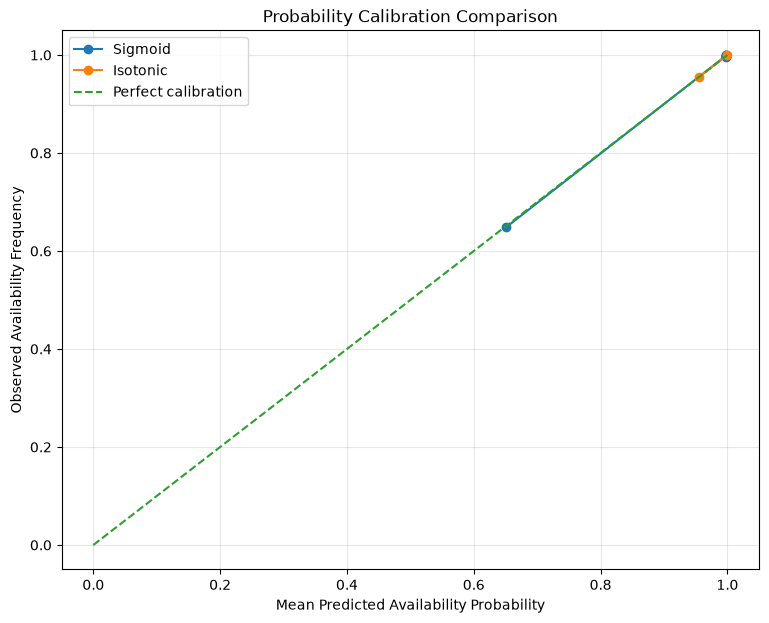

In [121]:
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve

plt.figure(figsize=(9, 7))

for method, model in calibrated_models.items():

    probabilities = model.predict_proba(X_calibration)

    available_index = list(model.classes_).index(1)
    p_available = probabilities[:, available_index]

    fraction_positive, mean_predicted = calibration_curve(
        y_calibration,
        p_available,
        n_bins=10,
        strategy="quantile"
    )

    plt.plot(
        mean_predicted,
        fraction_positive,
        marker="o",
        label=method.capitalize()
    )

plt.plot([0, 1], [0, 1], linestyle="--", label="Perfect calibration")

plt.xlabel("Mean Predicted Availability Probability")
plt.ylabel("Observed Availability Frequency")
plt.title("Probability Calibration Comparison")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [122]:
X_threshold = threshold_data[REDUCED_FEATURES]
y_threshold = threshold_data["target"].astype(int)

print("Threshold dataset:", X_threshold.shape)
print("Class distribution:")
print(y_threshold.value_counts(normalize=True))

Threshold dataset: (228374, 13)
Class distribution:
target
1    0.962299
0    0.037701
Name: proportion, dtype: float64


In [123]:
selected_calibrator = calibrated_models["sigmoid"]

threshold_probabilities = selected_calibrator.predict_proba(
    X_threshold
)

available_index = list(
    selected_calibrator.classes_
).index(1)

p_available = threshold_probabilities[:, available_index]
p_unavailable = 1 - p_available

print("Predictions generated:", len(p_available))
print("Probability range:",
      p_unavailable.min(), p_unavailable.max())

Predictions generated: 228374
Probability range: 0.0019156575309218216 0.9844583072723746


In [124]:
from sklearn.metrics import precision_recall_curve
import numpy as np
import pandas as pd

y_unavailable = (y_threshold == 0).astype(int)

precision, recall, thresholds = precision_recall_curve(
    y_unavailable,
    p_unavailable
)

# Calculate F1 for each threshold
f1_scores = (
    2 * precision[:-1] * recall[:-1]
    / (precision[:-1] + recall[:-1] + 1e-10)
)

best_index = np.argmax(f1_scores)

best_threshold = thresholds[best_index]

print("Best threshold:", round(best_threshold, 6))
print("Best Class-0 Precision:", round(precision[best_index], 6))
print("Best Class-0 Recall:", round(recall[best_index], 6))
print("Best Class-0 F1:", round(f1_scores[best_index], 6))

Best threshold: 0.249048
Best Class-0 Precision: 0.969317
Best Class-0 Recall: 0.906272
Best Class-0 F1: 0.936735


In [125]:
from sklearn.metrics import precision_score, recall_score, f1_score

threshold_comparison = []

for threshold in [0.5, best_threshold]:

    predictions = (
        p_unavailable >= threshold
    ).astype(int)

    threshold_comparison.append({
        "threshold": threshold,
        "precision_0": precision_score(
            y_unavailable, predictions, zero_division=0
        ),
        "recall_0": recall_score(
            y_unavailable, predictions, zero_division=0
        ),
        "f1_0": f1_score(
            y_unavailable, predictions, zero_division=0
        )
    })

threshold_comparison_df = pd.DataFrame(
    threshold_comparison
)

display(threshold_comparison_df)

,threshold,precision_0,recall_0,f1_0
0,0.500000,0.975374,0.878630,0.924478
1,0.249048,0.969317,0.906272,0.936735


In [126]:
SELECTED_UNAVAILABLE_THRESHOLD = best_threshold
SELECTED_AVAILABLE_THRESHOLD = 1 - best_threshold

print("Selected unavailable threshold:",
      SELECTED_UNAVAILABLE_THRESHOLD)

print("Shared evaluation threshold:",
      SELECTED_AVAILABLE_THRESHOLD)

Selected unavailable threshold: 0.2490475878557259
Shared evaluation threshold: 0.7509524121442741


In [127]:
from src.evaluation import (
    validate_prediction_output,
    evaluate_predictions,
    evaluate_by_horizon,
    evaluate_by_station_group
)

X_validation_reduced = validation[REDUCED_FEATURES]

final_calibrated_model = calibrated_models["sigmoid"]

start_time = time.perf_counter()

validation_probabilities = final_calibrated_model.predict_proba(
    X_validation_reduced
)

inference_time = time.perf_counter() - start_time

available_index = list(
    final_calibrated_model.classes_
).index(1)

p_available_validation = validation_probabilities[:, available_index]

y_pred_validation = (
    p_available_validation >= SELECTED_AVAILABLE_THRESHOLD
).astype(int)

final_predictions = pd.DataFrame({
    "station_id": validation["station_id"].values,
    "time": validation["time"].values,
    "target_time": validation["target_time"].values,
    "prediction_horizon": validation["prediction_horizon"].values,
    "y_true": validation["target"].astype(int).values,
    "y_pred": y_pred_validation,
    "y_prob": p_available_validation,
    "model_name": "random_forest",
    "model_version": "optimized_sigmoid",
    "threshold": SELECTED_AVAILABLE_THRESHOLD
})

print("Prediction output shape:", final_predictions.shape)
print("Inference time:", round(inference_time, 3), "seconds")

assert len(final_predictions) == len(validation)

print("\nPrediction generation successful.")

Prediction output shape: (618726, 10)
Inference time: 0.768 seconds

Prediction generation successful.


In [128]:
final_overall = evaluate_predictions(
    final_predictions,
    training_station_ids
)

display(final_overall)

,model_name,model_version,evaluation_group,n_stations,n_observations,accuracy,balanced_accuracy,precision_0,recall_0,f1_0,roc_auc,ap_0,brier_score,actual_0_predicted_0,actual_0_predicted_1,actual_1_predicted_0,actual_1_predicted_1
0,random_forest,optimized_sigmoid,overall,90,618726,0.99706,0.97922,0.969612,0.959753,0.964657,0.993712,0.978323,0.002893,24824,1041,778,592083


In [129]:
import inspect

print(inspect.signature(evaluate_predictions))
print(inspect.getsource(evaluate_predictions))

(predictions, training_station_ids)
def evaluate_predictions(predictions, training_station_ids):
    """Evaluate overall model performance."""

    validate_prediction_output(predictions)

    metrics = calculate_classification_metrics(
        predictions["y_true"],
        predictions["y_pred"],
        predictions["y_prob"]
    )

    result = {
        "model_name": predictions["model_name"].iloc[0],
        "model_version": predictions["model_version"].iloc[0],
        "evaluation_group": "overall",
        "n_stations": predictions["station_id"].nunique(),
        **metrics
    }

    return pd.DataFrame([result])



In [130]:
final_overall = evaluate_predictions(
    final_predictions,
    training_station_ids
)

display(final_overall)

,model_name,model_version,evaluation_group,n_stations,n_observations,accuracy,balanced_accuracy,precision_0,recall_0,f1_0,roc_auc,ap_0,brier_score,actual_0_predicted_0,actual_0_predicted_1,actual_1_predicted_0,actual_1_predicted_1
0,random_forest,optimized_sigmoid,overall,90,618726,0.99706,0.97922,0.969612,0.959753,0.964657,0.993712,0.978323,0.002893,24824,1041,778,592083


In [131]:
final_by_horizon = evaluate_by_horizon(
    final_predictions,
    training_station_ids
)

display(final_by_horizon)

,model_name,model_version,evaluation_group,prediction_horizon,n_stations,n_observations,accuracy,balanced_accuracy,precision_0,recall_0,f1_0,roc_auc,ap_0,brier_score,actual_0_predicted_0,actual_0_predicted_1,actual_1_predicted_0,actual_1_predicted_1
0,random_forest,optimized_sigmoid,horizon,30,90,206482,0.997714,0.983523,0.977089,0.968037,0.972542,0.994811,0.982423,0.002344,8359,276,196,197651
1,random_forest,optimized_sigmoid,horizon,40,90,206302,0.997218,0.980474,0.970984,0.962203,0.966573,0.994094,0.979270,0.002777,8299,326,248,197429
2,random_forest,optimized_sigmoid,horizon,60,90,205942,0.996247,0.973645,0.960706,0.948983,0.954809,0.991824,0.972892,0.003558,8166,439,334,197003


In [132]:
final_by_station = evaluate_by_station_group(
    final_predictions,
    training_station_ids
)

display(final_by_station)

,model_name,model_version,evaluation_group,n_stations,n_observations,accuracy,balanced_accuracy,precision_0,recall_0,f1_0,roc_auc,ap_0,brier_score,actual_0_predicted_0,actual_0_predicted_1,actual_1_predicted_0,actual_1_predicted_1
0,random_forest,optimized_sigmoid,seen,89,612854,0.997052,0.979436,0.969612,0.960198,0.964882,0.993925,0.978766,0.002901,24824,1029,778,586223
1,random_forest,optimized_sigmoid,unseen,1,5872,0.997956,0.500000,NaN,0.000000,0.000000,0.626863,0.003029,0.002041,0,12,0,5860


In [133]:
seen_results = final_by_station[
    final_by_station["evaluation_group"] == "seen"
]

final_seen_ap_0 = seen_results["ap_0"].iloc[0]

print("Final Seen Validation AP-0:",
      round(final_seen_ap_0, 6))

print("Final inference time:",
      round(inference_time, 3), "seconds")

Final Seen Validation AP-0: 0.978766
Final inference time: 0.768 seconds


In [134]:
validate_prediction_output(
    final_predictions,
    validation
)

True

In [135]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Access the trained Random Forest pipeline
rf_classifier = calibration_base_model.named_steps["classifier"]

# Get transformed feature names
preprocessor = calibration_base_model.named_steps["preprocessor"]

transformed_features = preprocessor.get_feature_names_out()

# Extract Random Forest feature importances
raw_importances = rf_classifier.feature_importances_

assert len(transformed_features) == len(raw_importances)

print("Transformed features:", len(transformed_features))
print("Original features:", len(REDUCED_FEATURES))


Transformed features: 103
Original features: 13


In [136]:
importance_data = pd.DataFrame({
    "transformed_feature": transformed_features,
    "importance": raw_importances
})

grouped_importance = []

for feature in REDUCED_FEATURES:

    matching = importance_data[
        importance_data["transformed_feature"].apply(
            lambda name: (
                name.split("__")[-1] == feature
                or name.split("__")[-1].startswith(feature + "_")
            )
        )
    ]

    grouped_importance.append({
        "feature": feature,
        "importance": matching["importance"].sum()
    })

feature_importance_df = pd.DataFrame(
    grouped_importance
).sort_values(
    "importance",
    ascending=False
).reset_index(drop=True)

feature_importance_df["importance_percentage"] = (
    feature_importance_df["importance"] * 100
)

display(feature_importance_df)

,feature,importance,importance_percentage
0,idle_lag_10,0.149488,14.948774
1,idle_lag_15,0.140796,14.079624
2,current_idle,0.135192,13.519220
3,idle_lag_40,0.134676,13.467599
4,idle_lag_5,0.133885,13.388517
5,idle_lag_120,0.097132,9.713173
6,idle_lag_30,0.080961,8.096138
7,idle_lag_60,0.080578,8.057795
8,station_id,0.036690,3.669041
9,hour,0.007075,0.707470


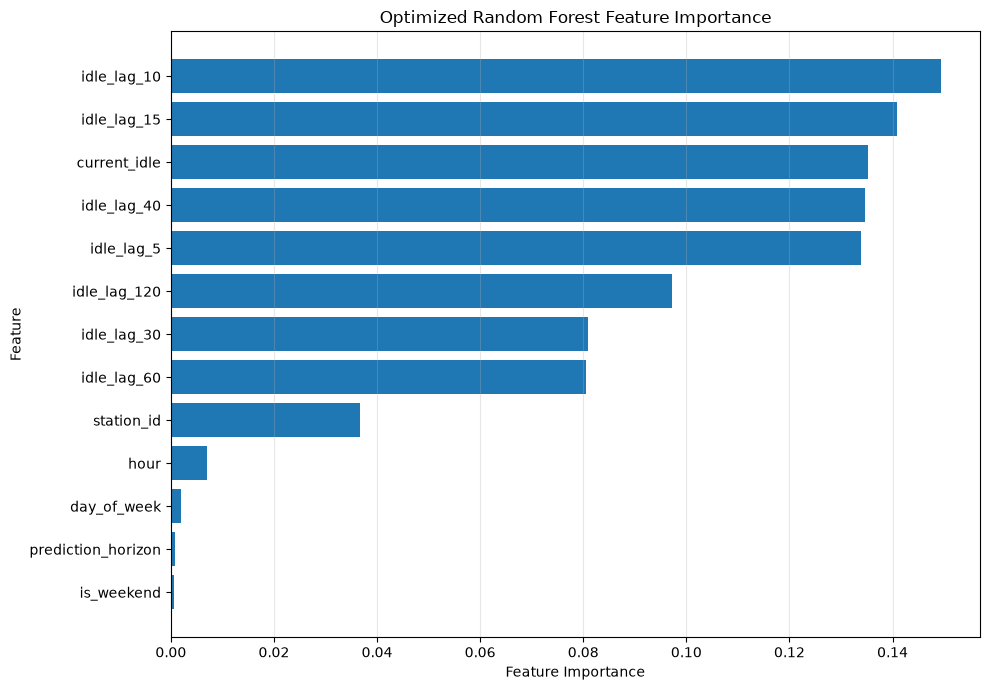

In [137]:
plt.figure(figsize=(10, 7))

plt.barh(
    feature_importance_df["feature"],
    feature_importance_df["importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Optimized Random Forest Feature Importance")

plt.gca().invert_yaxis()
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [138]:
from pathlib import Path

output_dir = Path("outputs/tables")
output_dir.mkdir(parents=True, exist_ok=True)

feature_importance_df.to_csv(
    output_dir / "random_forest_feature_importance.csv",
    index=False
)

print("Feature importance results exported.")

Feature importance results exported.


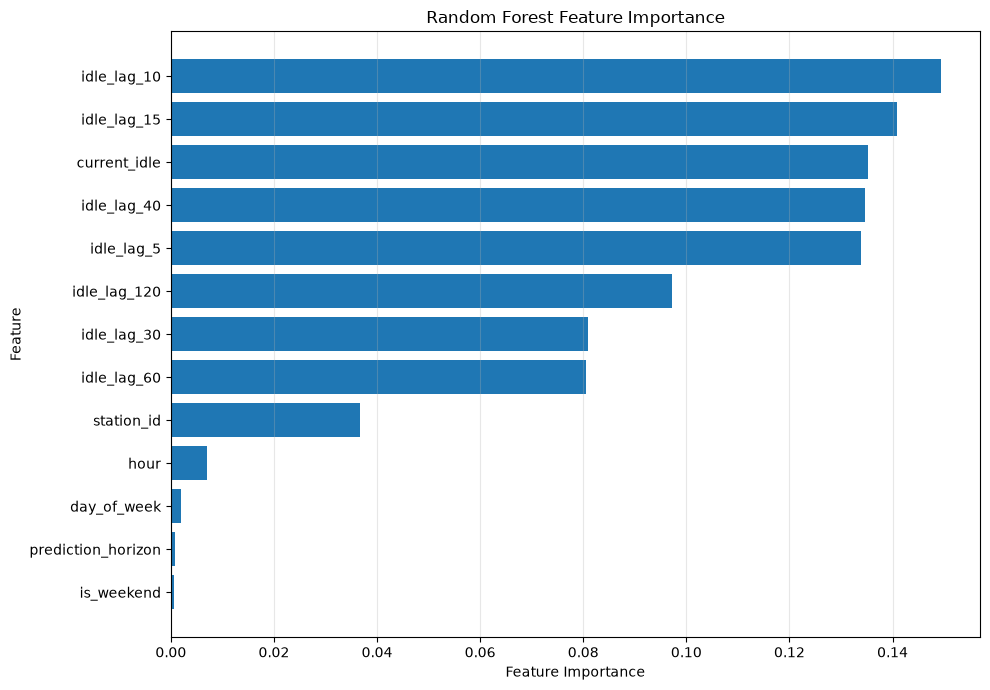

In [139]:
from pathlib import Path

figure_dir = PROJECT_ROOT / "outputs" / "figures"
figure_dir.mkdir(parents=True, exist_ok=True)

plt.figure(figsize=(10, 7))

plt.barh(
    feature_importance_df["feature"],
    feature_importance_df["importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Random Forest Feature Importance")

plt.gca().invert_yaxis()
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()

plt.savefig(
    figure_dir / "random_forest_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [140]:
print(
    Path("outputs/figures/random_forest_feature_importance.png").exists()
)

True


In [141]:
output_dir = PROJECT_ROOT / "outputs" / "tables"
output_dir.mkdir(parents=True, exist_ok=True)

feature_importance_df.to_csv(
    output_dir / "random_forest_feature_importance.csv",
    index=False
)

print("Feature importance CSV exported successfully.")

Feature importance CSV exported successfully.


### 13.2 Feature Importance Findings

The feature importance analysis revealed that historical charging station occupancy features dominate the Random Forest model's predictions.

The most influential features were `idle_lag_10`, `idle_lag_15`, `current_idle`, `idle_lag_40`, and `idle_lag_5`.

These results indicate that recent and historical station availability patterns provide the most important information for predicting future availability.

The `station_id` feature had a relatively smaller contribution, suggesting that historical occupancy patterns are more influential than station identity alone.

Calendar-related features, including `hour`, `day_of_week`, and `is_weekend`, demonstrated relatively low importance.

Overall, the findings support the importance of temporal features in charging station availability prediction. However, impurity-based feature importance measures indicate model reliance rather than causal relationships or the independent predictive contribution of each feature.

## 14. Optimized Model Artifact Export

Save the trained calibrated Random Forest model, validation
predictions, and evaluation results for reproducibility
and cross-model comparison.

In [142]:
# Configure artifact directories
MODEL_DIR = PROJECT_ROOT / "outputs" / "models" / "random_forest"
PREDICTION_DIR = PROJECT_ROOT / "outputs" / "predictions" / "random_forest"
TABLE_DIR = PROJECT_ROOT / "outputs" / "tables"

for directory in [MODEL_DIR, PREDICTION_DIR, TABLE_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

# Save the trained calibrated model
optimized_model_path = MODEL_DIR / "optimized_sigmoid_model.joblib"

joblib.dump(
    final_calibrated_model,
    optimized_model_path,
    compress=3
)

# Save validation predictions
optimized_prediction_path = (
    PREDICTION_DIR / "optimized_sigmoid_validation.parquet"
)

final_predictions.to_parquet(
    optimized_prediction_path,
    index=False
)

# Export standardized evaluation tables
from src.evaluation import export_evaluation_results

optimized_tables = export_evaluation_results(
    final_predictions,
    training_station_ids,
    validation,
    output_dir=TABLE_DIR
)

print("Model saved:", optimized_model_path)
print("Predictions saved:", optimized_prediction_path)
print("Evaluation tables saved:", TABLE_DIR)

Saved: /Users/nehiraydemir/VoltAhead/outputs/tables/random_forest_optimized_sigmoid_overall.csv
Saved: /Users/nehiraydemir/VoltAhead/outputs/tables/random_forest_optimized_sigmoid_by_horizon.csv
Saved: /Users/nehiraydemir/VoltAhead/outputs/tables/random_forest_optimized_sigmoid_by_station_group.csv
Model saved: /Users/nehiraydemir/VoltAhead/outputs/models/random_forest/optimized_sigmoid_model.joblib
Predictions saved: /Users/nehiraydemir/VoltAhead/outputs/predictions/random_forest/optimized_sigmoid_validation.parquet
Evaluation tables saved: /Users/nehiraydemir/VoltAhead/outputs/tables


## 15. Experiment Results and Metadata Export

Save the experimental results and optimized model metadata
to document the model development and selection process.

In [143]:
class_weight_results_df = pd.DataFrame(class_weight_results)

experiment_tables = {
    "hyperparameter_search": optimization_results_df,
    "hyperparameter_comparison": comparison,
    "class_weight_comparison": class_weight_results_df,
    "feature_selection": feature_comparison,
    "calibration_comparison": calibration_results_df,
    "threshold_comparison": threshold_comparison_df
}

for name, dataframe in experiment_tables.items():
    path = TABLE_DIR / f"random_forest_{name}.csv"
    dataframe.to_csv(path, index=False)
    print("Saved:", path.name)

Saved: random_forest_hyperparameter_search.csv
Saved: random_forest_hyperparameter_comparison.csv
Saved: random_forest_class_weight_comparison.csv
Saved: random_forest_feature_selection.csv
Saved: random_forest_calibration_comparison.csv
Saved: random_forest_threshold_comparison.csv


## 16. Initial vs. Optimized Model Comparison

Compare both Random Forest configurations using the shared
validation dataset and evaluation metrics.

The primary model selection criterion is Class-0 Average
Precision (AP-0) on seen validation stations.

In [144]:
# Compare overall validation performance
overall_comparison = pd.concat(
    [initial_overall, final_overall],
    ignore_index=True
)

# Compare performance across prediction horizons
horizon_comparison = pd.concat(
    [initial_by_horizon, final_by_horizon],
    ignore_index=True
)

# Compare seen and unseen station performance
station_comparison = pd.concat(
    [initial_by_station_group, final_by_station],
    ignore_index=True
)

comparison_tables = {
    "overall": overall_comparison,
    "by_horizon": horizon_comparison,
    "by_station_group": station_comparison
}

for name, dataframe in comparison_tables.items():
    path = TABLE_DIR / f"random_forest_comparison_{name}.csv"
    dataframe.to_csv(path, index=False, na_rep="N/A")
    print("Saved:", path.name)

display(overall_comparison)

Saved: random_forest_comparison_overall.csv
Saved: random_forest_comparison_by_horizon.csv
Saved: random_forest_comparison_by_station_group.csv


,model_name,model_version,evaluation_group,n_stations,n_observations,accuracy,balanced_accuracy,precision_0,recall_0,f1_0,roc_auc,ap_0,brier_score,actual_0_predicted_0,actual_0_predicted_1,actual_1_predicted_0,actual_1_predicted_1
0,random_forest,initial,overall,90,618726,0.996905,0.976736,0.970752,0.954726,0.962673,0.994443,0.979174,0.002751,24694,1171,744,592117
1,random_forest,optimized_sigmoid,overall,90,618726,0.997060,0.979220,0.969612,0.959753,0.964657,0.993712,0.978323,0.002893,24824,1041,778,592083


In [145]:
# Select the best Random Forest configuration
selection_comparison = station_comparison.loc[
    station_comparison["evaluation_group"] == "seen"
].copy()

selection_comparison = selection_comparison.sort_values(
    "ap_0", ascending=False
).reset_index(drop=True)

selection_columns = [
    "model_version",
    "ap_0",
    "roc_auc",
    "balanced_accuracy",
    "precision_0",
    "recall_0",
    "f1_0",
    "brier_score"
]

display(selection_comparison[selection_columns])

SELECTED_MODEL_VERSION = selection_comparison.loc[
    0, "model_version"
]

selection_comparison[selection_columns].to_csv(
    TABLE_DIR / "random_forest_model_selection.csv",
    index=False
)

print("Selected Random Forest model:", SELECTED_MODEL_VERSION)

,model_version,ap_0,roc_auc,balanced_accuracy,precision_0,recall_0,f1_0,brier_score
0,initial,0.979618,0.994732,0.976951,0.970752,0.955170,0.962898,0.002755
1,optimized_sigmoid,0.978766,0.993925,0.979436,0.969612,0.960198,0.964882,0.002901


Selected Random Forest model: initial


## 17. Final Conclusion

Two Random Forest configurations were developed and evaluated
using the shared chronological validation dataset.

The optimization process included hyperparameter search,
class weight analysis, feature selection, probability
calibration, and classification threshold optimization.

The optimized model improved Class-0 recall, Class-0 F1,
and balanced accuracy. However, the initial model achieved
a higher Class-0 Average Precision on seen validation stations
(0.979618 compared to 0.978766).

Since seen-validation AP-0 is the primary model selection
criterion, the initial Random Forest was selected for
cross-model comparison.

The selected configuration consists of:

- 16 input features
- 100 decision trees
- Maximum tree depth of 15
- Minimum samples per leaf of 5
- Square-root feature sampling
- No class weighting
- No probability calibration
- Classification threshold of 0.5
- Random seed of 42

Both configurations demonstrated strong performance on
seen stations. However, neither correctly classified the
12 unavailable observations at the unseen validation station.
Therefore, generalization to unseen stations remains a
limitation.

The calibration methods were evaluated on the calibration
dataset itself without an uncalibrated reference model.
Consequently, an independent improvement from calibration
cannot be established.

Both model artifacts and their experimental results were
preserved for reproducibility and further analysis.

The test dataset remains unused and is reserved for the
final evaluation after cross-model selection.

## 18. Artifact Verification

Verify that the saved optimized model reproduces the original
prediction probabilities and that the exported predictions
comply with the shared evaluation schema.

In [146]:
# Reload the saved optimized model
loaded_optimized_model = joblib.load(
    optimized_model_path
)

# Select deterministic verification inputs
verification_sample = validation[
    REDUCED_FEATURES
].iloc[:1000]

original_probabilities = final_calibrated_model.predict_proba(
    verification_sample
)

loaded_probabilities = loaded_optimized_model.predict_proba(
    verification_sample
)

# Verify probability consistency
np.testing.assert_allclose(
    original_probabilities,
    loaded_probabilities,
    rtol=0,
    atol=1e-12
)

# Verify exported predictions
saved_optimized_predictions = pd.read_parquet(
    optimized_prediction_path
)

validate_prediction_output(
    saved_optimized_predictions,
    validation
)

print("Optimized model reload verification passed.")
print("Saved prediction verification passed.")
print("Selected Random Forest model:", SELECTED_MODEL_VERSION)

Optimized model reload verification passed.
Saved prediction verification passed.
Selected Random Forest model: initial


In [147]:
import subprocess

optimized_metadata = {
    "model_name": "random_forest",
    "model_version": "optimized_sigmoid",
    "dataset_version": "VOLTAHEAD-DATA-V1",

    "features": REDUCED_FEATURES,
    "n_features": len(REDUCED_FEATURES),
    "hyperparameters": DEFAULT_RF_PARAMS,

    "training_rows": len(final_fit_data),
    "calibration_rows": len(calibration_data),
    "threshold_selection_rows": len(threshold_data),
    "validation_rows": len(validation),

    "calibration_method": "sigmoid",

    "available_threshold": float(SELECTED_AVAILABLE_THRESHOLD),
    "unavailable_threshold": float(SELECTED_UNAVAILABLE_THRESHOLD),

    "base_training_time_seconds": float(base_training_time),
    "validation_inference_time_seconds": float(inference_time),

    "primary_metric": "seen_validation_ap_0",
    "primary_metric_value": float(final_seen_ap_0),

    "selected_for_cross_model_comparison": False,

    "environment": {
        "python_version": platform.python_version(),
        "scikit_learn_version": sklearn.__version__,
        "numpy_version": np.__version__,
        "pandas_version": pd.__version__,
        "joblib_version": joblib.__version__,
        "platform": platform.platform(),
        "cpu_cores": psutil.cpu_count(),
        "ram_gb": round(psutil.virtual_memory().total / 1024**3, 2)
    },

    "git_commit": subprocess.check_output(
        ["git", "rev-parse", "HEAD"],
        cwd=PROJECT_ROOT,
        text=True
    ).strip(),

    "git_working_tree_dirty": bool(
        subprocess.check_output(
            ["git", "status", "--porcelain"],
            cwd=PROJECT_ROOT,
            text=True
        ).strip()
    ),

    "test_set_used": False
}

metadata_path = (
    TABLE_DIR / "random_forest_optimized_sigmoid_metadata.json"
)

with open(metadata_path, "w") as file:
    json.dump(optimized_metadata, file, indent=4)

print("Metadata saved:", metadata_path)

Metadata saved: /Users/nehiraydemir/VoltAhead/outputs/tables/random_forest_optimized_sigmoid_metadata.json
